# Introduktion 

Syftet med analysen är att beskriva deltagarnas hälsa och undersöka om rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare. Med beskrivande statistik och visualiseringar sammanfattas datan. Simulering används för att undersöka andelen personer med sjukdom, och konfidensintervall används för att uppskatta osäkerheten i det genomsnittliga blodtrycket.

In [17]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, math, scipy


df = pd.read_csv("data/health_study_dataset.csv")

display(df.info())
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


None

,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


# Vi kan se att det inte finns några NaN i någon av kolumnerna, därför kommer jag inte använda mig av dropna(), vilket annars ofta behövs

# Beskrivande analys

medel, median, min, max för: age, weight, height, systolic_bp, cholesterol

In [2]:
columns = ["age", "height", "weight", "systolic_bp", "cholesterol"]

summary = df[columns].agg(["mean", "median", "min", "max"]).round(2)
display(summary)

,age,height,weight,systolic_bp,cholesterol
mean,49.43,171.85,73.41,149.18,4.93
median,50.00,171.35,73.20,149.40,4.97
min,18.00,144.40,33.70,106.80,2.50
max,90.00,200.40,114.40,185.90,7.88


# Visualiseringar

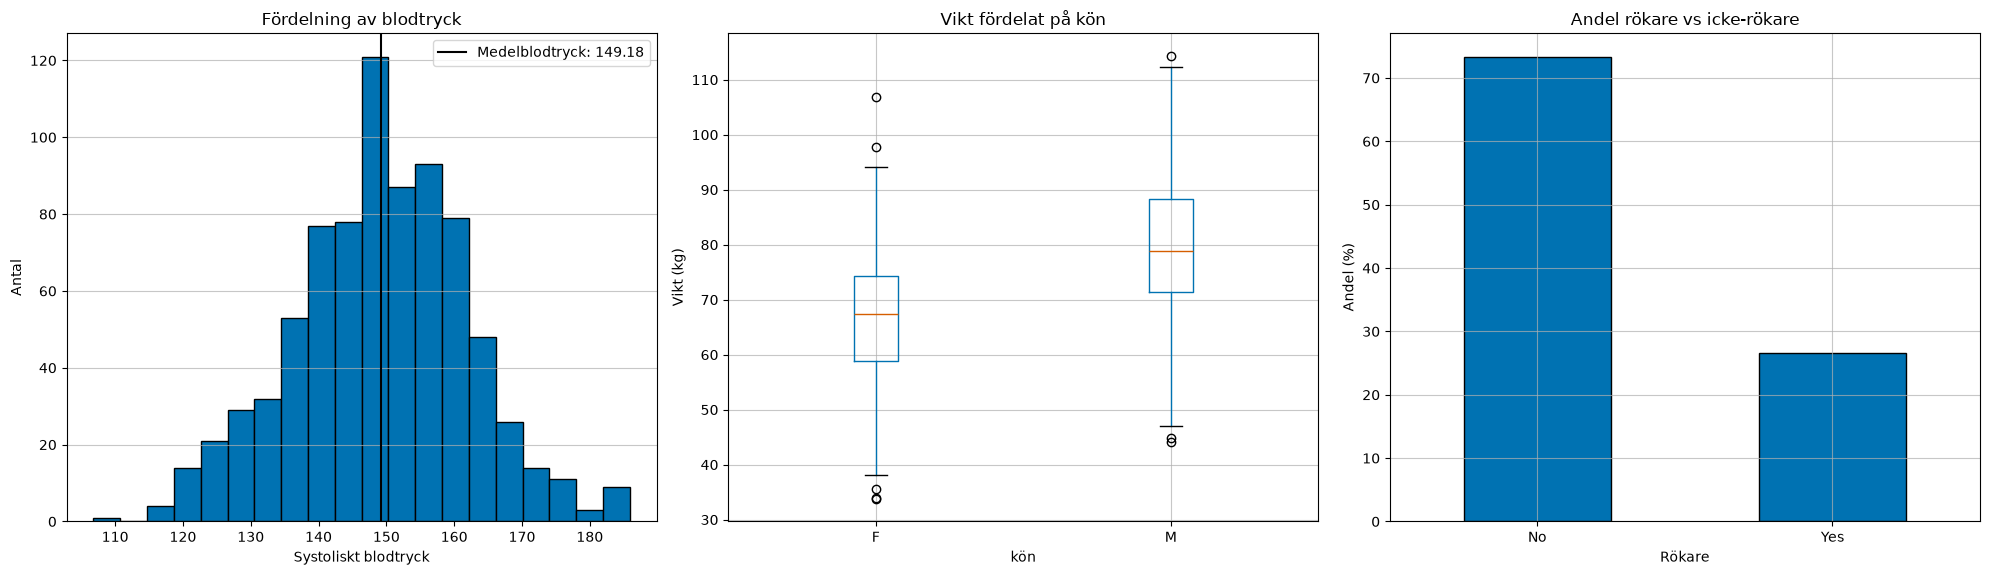

In [3]:
"""deklarerar storlek och grid på alla figurer"""
plt.style.use("seaborn-v0_8-colorblind")
plt.rcParams["figure.figsize"] = (20, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["grid.alpha"] = (0.7)

fig, axes = plt.subplots(1, 3)

#Histogram över blodtryck
axes[0].hist(df["systolic_bp"], bins=20, edgecolor="black")
axes[0].set_title("Fördelning av blodtryck")
axes[0].set_xlabel("Systoliskt blodtryck")
axes[0].set_ylabel("Antal")
axes[0].axvline(df["systolic_bp"].mean(), color="black", label=f"Medelblodtryck: {df['systolic_bp'].mean():.2f}")
axes[0].legend()

#boxplot över vikt per kön
df.boxplot(column="weight", by="sex", ax=axes[1])
axes[1].set_title("Vikt fördelat på kön")
axes[1].set_xlabel("kön")
axes[1].set_ylabel("Vikt (kg)")
fig.suptitle("")


#Stapeldiagram över andel rökare och icke-rökare
smoker_percent = df["smoker"].value_counts(normalize=True) * 100

smoker_percent.plot.bar(ax=axes[2], edgecolor="black")
axes[2].set_title("Andel rökare vs icke-rökare")
axes[2].set_xlabel("Rökare")
axes[2].set_ylabel("Andel (%)")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()





# Simulering

In [4]:
np.random.seed(42)

n = df["disease"].count()
disease_probability = (df["disease"]).mean()
print(f"Andel med sjukdom: {disease_probability:.2%} av {n} = {(disease_probability * n):.0f} personer")

simulated_disease = np.random.choice(
    [0,1],
    size=1000,
    p=[1 - disease_probability, disease_probability]
)

print(
    f"Den observerade andelen är {disease_probability:.2%} "
    f"och den simulerade andelen är {simulated_disease.mean():.2%}. "
    f"Med samma sannolikhet förväntas ungefär "
    f"{disease_probability * 1000:.0f} av 1000 personer ha sjukdomen."
)



Andel med sjukdom: 5.88% av 800 = 47 personer
Den observerade andelen är 5.88% och den simulerade andelen är 5.60%. Med samma sannolikhet förväntas ungefär 59 av 1000 personer ha sjukdomen.


# Tolkning

Den observerade andelen med sjukdom är 5,88 %, medan den simulerade andelen är 5,60 %. Skillnaden är cirka 0,28 procentenheter och beror på slumpvariationen i simuleringen. Andelarna behöver därför inte bli exakt lika.

# Konfidensintervall med normalapproximation och bootstrap

Medelvärde: 149.18
95% ci med normalapproximation: (148.29, 150.07)
95% bootstrapintervall: (148.31, 150.10)
Bredd normalapproximation: 1.77 mmHg
Bredd bootstrap: 1.79 mmHg


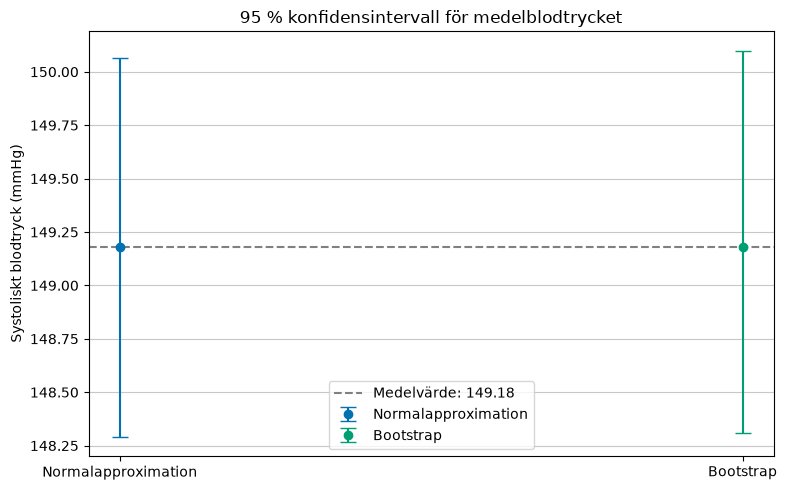

In [8]:
np.random.seed(42)
bp = df["systolic_bp"] #bp = bloodpressure

"""
95%-ci med normalapproximation
"""
def ci_normal(bp):

    n = len(bp)
    bp_mean = np.mean(bp)
    bp_std = np.std(bp, ddof=1)
    se = (bp_std / math.sqrt(n))

    z_critical = 1.96
    half_width = z_critical * se
    lo, hi = bp_mean - half_width, bp_mean + half_width
    return (lo, hi), bp_mean, bp_std, n

(lo, hi), bp_mean, bp_std, n = ci_normal(bp)

"""95%-ci med bootstrap"""
def ci_bootstrap(bp, n=1000):
    bootstrap_means = []

    for _ in range(n):
        sample = np.random.choice(
            bp,
            size=len(bp),
            replace=True
        )
        bootstrap_means.append(np.mean(sample))
    blo, bhi = np.percentile(bootstrap_means, [2.5, 97.5])
    return (blo, bhi)

(blo, bhi) = ci_bootstrap(bp)


print(f"Medelvärde: {bp.mean():.2f}")
print(f"95% ci med normalapproximation: ({lo:.2f}, {hi:.2f})")
print(f"95% bootstrapintervall: ({blo:.2f}, {bhi:.2f})")
print(f"Bredd normalapproximation: {hi - lo:.2f} mmHg")
print(f"Bredd bootstrap: {bhi - blo:.2f} mmHg")


fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    x=0,
    y=bp_mean,
    yerr=[[bp_mean - lo], [hi - bp_mean]],
    fmt="o",
    capsize=6,
    label="Normalapproximation"
)
ax.errorbar(
    x=1,
    y=bp_mean,
    yerr=[[bp_mean - blo], [bhi - bp_mean]],
    fmt="o",
    capsize=6,
    label="Bootstrap"
)
ax.set_xticks([0, 1], ["Normalapproximation", "Bootstrap"])
ax.set_ylabel("Systoliskt blodtryck (mmHg)")
ax.set_title("95 % konfidensintervall för medelblodtrycket")
plt.axhline(bp_mean, label=f"Medelvärde: {bp_mean:.2f}", color="grey", linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()


# Jämförelse CI

De två metoderna ger nästan identiska konfidensintervall. Bootstrapintervallet är marginellt bredare och något förskjutet uppåt, men skillnaderna är små (ca 0.02 mmHg). Slutsatsen om det genomsnittliga systoliska blodtrycket påverkas därför mycket lite av vilken metod som används.

# -----------------------------------------------------------------

# Hypotesprövning

Hypotes 1: Rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare

Hypotes 2: Rökare har inte högre genomsnittligt systoliskt blodtryck än icke-rökare

Signifikansnivå på p-värde = 0.05

In [26]:
bp_smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"]
bp_non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"]

observed_diff = bp_smokers.mean() - bp_non_smokers.mean()
print(f"Observerad skillnad: {observed_diff:.2f} mmHg")

pool_mean = pd.concat([bp_smokers, bp_non_smokers]).mean()

"""
Nollanalys
"""
smokers_null = bp_smokers - bp_smokers.mean() + pool_mean
non_smokers_null = bp_non_smokers - bp_non_smokers.mean() + pool_mean


if smokers_null.mean() == non_smokers_null.mean():
    print(f"Samma medelvärde ({smokers_null.mean():.2f} vs {non_smokers_null.mean():.2f})")

np.random.seed(42)
null_differences = []

for _ in range(10000):
    sample_smokers = np.random.choice(
        smokers_null,
        size=len(smokers_null),
        replace=True
    )
    sample_non_smokers = np.random.choice(
        non_smokers_null,
        size=len(non_smokers_null),
        replace=True
    )

    diff = np.mean(sample_smokers) - np.mean(sample_non_smokers)
    null_differences.append(diff)

null_differences = np.array(null_differences)

#P-värde
p_value = (
    np.sum(null_differences >= observed_diff) + 1
) / (len(null_differences) + 1)

print(f"P-värde: {p_value:.4f}")

if p_value < 0.05:
    print("Vi förkastar nollhypotesen.")
else:
    print("Vi kan inte förkasta nollhypotesen.")

#Cohens d
# Antal observationer och stickprovsstandardavvikelser.
n_smokers = len(bp_smokers)
n_non_smokers = len(bp_non_smokers)

std_smokers = np.std(bp_smokers, ddof=1)
std_non_smokers = np.std(bp_non_smokers, ddof=1)

# Sammanvägd standardavvikelse (pooled standard deviation).
pooled_std = np.sqrt(
    (
        (n_smokers - 1) * std_smokers**2
        + (n_non_smokers - 1) * std_non_smokers**2
    )
    / (n_smokers + n_non_smokers - 2)
)

cohens_d = (
    bp_smokers.mean() - bp_non_smokers.mean()
) / pooled_std

print(f"Cohen's d: {cohens_d:.3f}")

Observerad skillnad: 0.47 mmHg
Samma medelvärde (149.18 vs 149.18)
P-värde: 0.3332
Vi kan inte förkasta nollhypotesen.
Cohen's d: 0.037


# Resultat

Rökarna hade i snitt 0,47 mmHg högre systoliskt blodtryck än icke-rökarna i datan. Men hur tydlig är den skillnaden?

Det ensidiga bootstraptestet gav ett p-värde på 0,3332, vilket är över gränsen 0,05. En sådan skillnad är alltså inte särskilt ovanlig även om grupperna egentligen har samma medelblodtryck.

Vi kan därför inte förkasta nollhypotesen. Datan ger inte tillräckligt stöd för att rökare har högre medelblodtryck, men det betyder inte att vi har visat att grupperna är lika.

Skillnaden är också mycket liten jämfört med hur blodtrycket varierar inom grupperna, vilket Cohen’s d på 0,037 visar. Den observerade skillnaden mellan rökare och icke-rökare är alltså mycket liten i förhållande till spridningen inom grupperna. Analysen tar däremot inte hänsyn till andra faktorer, som ålder och vikt, och kan inte visa hur rökning i sig påverkar blodtrycket.